In [1]:
from scipy import stats

data1 = [12, 14, 15, 13, 16, 14, 15]
data2 = [18, 20, 19, 21, 17, 22, 20]
data3 = [10, 11, 9, 12, 10, 11, 13]

# 1. One-sample t-test (compare sample mean to a known population mean)
t_stat, p_val = stats.ttest_1samp(data1, popmean=15)

# 2. Independent two-sample t-test (Welch's t-test if equal_var=False)
t_stat, p_val = stats.ttest_ind(data1, data2, equal_var=False)

# 3. Paired sample t-test (before/after on the same subjects)
t_stat, p_val = stats.ttest_rel(data1, data2)

# 4. One-way ANOVA (compare means across 3 or more groups)
f_stat, p_val = stats.f_oneway(data1, data2, data3)

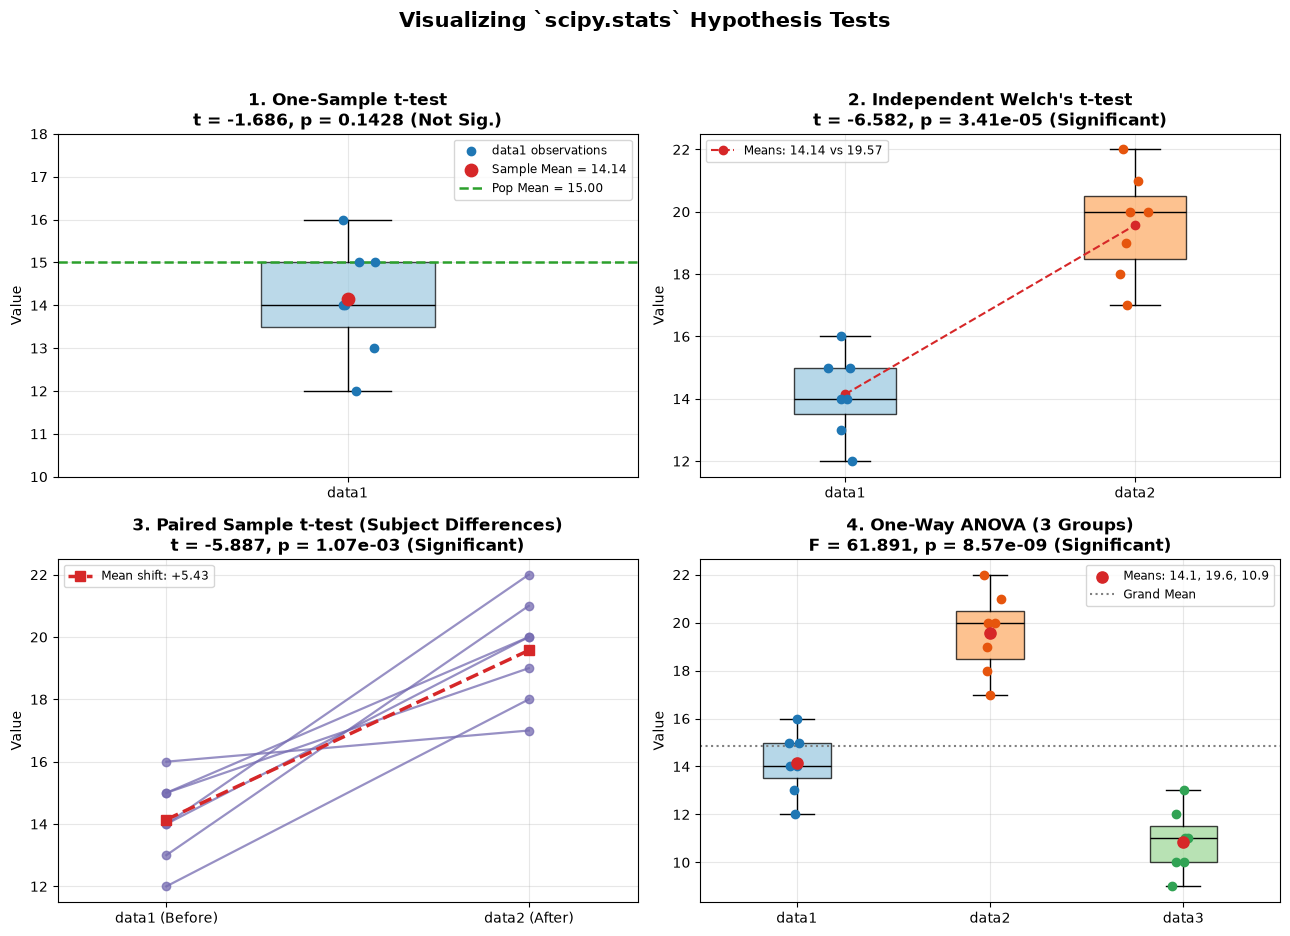

In [2]:
from scipy import stats

data1 = [12, 14, 15, 13, 16, 14, 15]
data2 = [18, 20, 19, 21, 17, 22, 20]
data3 = [10, 11, 9, 12, 10, 11, 13]

# 1. One-sample t-test (compare sample mean to a known population mean)
t_stat, p_val = stats.ttest_1samp(data1, popmean=15)
t1, p1 = t_stat, p_val

# 2. Independent two-sample t-test (Welch's t-test if equal_var=False)
t_stat, p_val = stats.ttest_ind(data1, data2, equal_var=False)
t2, p2 = t_stat, p_val

# 3. Paired sample t-test (before/after on the same subjects)
t_stat, p_val = stats.ttest_rel(data1, data2)
t3, p3 = t_stat, p_val

# 4. One-way ANOVA (compare means across 3 or more groups)
f_stat, p_val = stats.f_oneway(data1, data2, data3)
f4, p4 = f_stat, p_val

# --- Visualization of the 4 tests ---
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
fig.suptitle("Visualizing `scipy.stats` Hypothesis Tests", fontsize=15, fontweight='bold')
np.random.seed(42)

# Panel 1: One-sample t-test (data1 vs popmean=15)
ax = axes[0, 0]
ax.boxplot(data1, positions=[1], widths=0.3, patch_artist=True,
           boxprops=dict(facecolor='#9ecae1', alpha=0.7), medianprops=dict(color='black'))
ax.scatter(np.random.normal(1, 0.03, size=len(data1)), data1, color='#1f77b4', zorder=4, label='data1 observations')
mean1 = np.mean(data1)
ax.scatter([1], [mean1], color='#d62728', s=80, zorder=5, label=f'Sample Mean = {mean1:.2f}')
ax.axhline(15, color='#2ca02c', linestyle='--', lw=1.8, label='Pop Mean = 15.00')
ax.set_xticks([1])
ax.set_xticklabels(['data1'])
ax.set_xlim(0.5, 1.5)
ax.set_ylim(10, 18)
ax.set_ylabel('Value')
ax.set_title(f'1. One-Sample t-test\nt = {t1:.3f}, p = {p1:.4f} (Not Sig.)', fontweight='bold')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(True, alpha=0.3)

# Panel 2: Independent two-sample t-test (data1 vs data2)
ax = axes[0, 1]
bp = ax.boxplot([data1, data2], positions=[1, 2], widths=0.35, patch_artist=True,
                medianprops=dict(color='black'))
for patch, color in zip(bp['boxes'], ['#9ecae1', '#fdae6b']):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax.scatter(np.random.normal(1, 0.03, size=len(data1)), data1, color='#1f77b4', zorder=4)
ax.scatter(np.random.normal(2, 0.03, size=len(data2)), data2, color='#e6550d', zorder=4)
means2 = [np.mean(data1), np.mean(data2)]
ax.plot([1, 2], means2, 'o--', color='#d62728', lw=1.5, label=f'Means: {means2[0]:.2f} vs {means2[1]:.2f}')
ax.set_xticks([1, 2])
ax.set_xticklabels(['data1', 'data2'])
ax.set_ylabel('Value')
ax.set_title(f"2. Independent Welch's t-test\nt = {t2:.3f}, p = {p2:.2e} (Significant)", fontweight='bold')
ax.legend(loc='upper left', fontsize=8.5)
ax.grid(True, alpha=0.3)

# Panel 3: Paired sample t-test (subject-by-subject slope chart)
ax = axes[1, 0]
for i in range(len(data1)):
    ax.plot([1, 2], [data1[i], data2[i]], 'o-', color='#756bb1', alpha=0.75, lw=1.6)
ax.plot([1, 2], [np.mean(data1), np.mean(data2)], 's--', color='#d62728', lw=2.5, markersize=7,
        label=f'Mean shift: +{np.mean(np.array(data2)-np.array(data1)):.2f}')
ax.set_xticks([1, 2])
ax.set_xticklabels(['data1 (Before)', 'data2 (After)'])
ax.set_xlim(0.7, 2.3)
ax.set_ylabel('Value')
ax.set_title(f'3. Paired Sample t-test (Subject Differences)\nt = {t3:.3f}, p = {p3:.2e} (Significant)', fontweight='bold')
ax.legend(loc='upper left', fontsize=8.5)
ax.grid(True, alpha=0.3)

# Panel 4: One-way ANOVA (data1, data2, data3)
ax = axes[1, 1]
bp3 = ax.boxplot([data1, data2, data3], positions=[1, 2, 3], widths=0.35, patch_artist=True,
                 medianprops=dict(color='black'))
for patch, color in zip(bp3['boxes'], ['#9ecae1', '#fdae6b', '#a1d99b']):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
for idx, (d, c) in enumerate(zip([data1, data2, data3], ['#1f77b4', '#e6550d', '#31a354']), start=1):
    ax.scatter(np.random.normal(idx, 0.03, size=len(d)), d, color=c, zorder=4)
means3 = [np.mean(data1), np.mean(data2), np.mean(data3)]
ax.scatter([1, 2, 3], means3, color='#d62728', s=65, zorder=5,
           label=f'Means: {means3[0]:.1f}, {means3[1]:.1f}, {means3[2]:.1f}')
ax.axhline(np.mean(data1 + data2 + data3), color='gray', linestyle=':', lw=1.5, label='Grand Mean')
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['data1', 'data2', 'data3'])
ax.set_ylabel('Value')
ax.set_title(f'4. One-Way ANOVA (3 Groups)\nF = {f4:.3f}, p = {p4:.2e} (Significant)', fontweight='bold')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()